
# Employee Performance Prediction

## Project Objective
Build a machine learning classification model to predict employee performance categories using employee-related features.

## Machine Learning Approach
- Data exploration and preprocessing
- Missing-value imputation and categorical encoding
- Decision Tree, Random Forest, Extra Trees, and CatBoost
- Hyperparameter tuning using GridSearchCV
- Model evaluation using accuracy, precision, recall, F1-score, and a confusion matrix

## Best Validation Result
Tuned Random Forest achieved 88.75% validation accuracy among the tested models.

## Tools and Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, CatBoost, Google Colab




In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [4]:
from google.colab import files

uploaded = files.upload()

Saving perf_test.csv to perf_test (2).csv
Saving perf_train.csv to perf_train.csv
Saving sample_submission.csv to sample_submission.csv


In [6]:
train = pd.read_csv("perf_train.csv")
test = pd.read_csv("perf_test.csv")
sample_submission = pd.read_csv("sample_submission.csv")


In [7]:
print("Training data shape:", train.shape)
print("Testing data shape:", test.shape)
print("Sample submission shape:", sample_submission.shape)

Training data shape: (2000, 22)
Testing data shape: (500, 21)
Sample submission shape: (500, 2)


In [8]:
train.head()

,Employee_ID,Age,Gender,City,Education_Level,Department,Experience_Years,Monthly_Salary,Projects_Completed,Training_Hours,...,Job_Satisfaction,Manager_Rating,Overtime_Hours,Commute_Time_Min,Laptop_Issue_Count,Cafeteria_Rating,Internet_Stability,Last_Promotion_Years,Absenteeism_Days,Performance_Category
0,10001,49.0,Male,Bengaluru,Post Graduate,Sales,NaN,NaN,15.0,20.0,...,3.0,3.2,43.0,11.0,3.0,1.0,Good,2.1,1.0,Average Performer
1,10002,35.0,Female,Bengaluru,Post Graduate,Analytics,0.8,129555.0,15.0,163.0,...,4.0,2.3,43.0,128.0,6.0,5.0,Average,0.8,18.0,Low Performer
2,10003,28.0,Female,NaN,Graduate,Finance,12.7,55760.0,NaN,213.0,...,1.0,4.2,50.0,34.0,1.0,4.0,Poor,1.3,12.0,Average Performer
3,10004,41.0,Male,Hyderabad,Graduate,Sales,4.9,128174.0,NaN,209.0,...,2.0,4.5,78.0,168.0,7.0,5.0,Good,4.2,11.0,Average Performer
4,10005,39.0,Male,NaN,Graduate,Sales,1.2,145192.0,5.0,117.0,...,3.0,4.2,20.0,117.0,9.0,2.0,Excellent,2.5,24.0,Low Performer


In [11]:
print(train.columns.tolist())

['Employee_ID', 'Age', 'Gender', 'City', 'Education_Level', 'Department', 'Experience_Years', 'Monthly_Salary', 'Projects_Completed', 'Training_Hours', 'Certifications', 'Work_Life_Balance', 'Job_Satisfaction', 'Manager_Rating', 'Overtime_Hours', 'Commute_Time_Min', 'Laptop_Issue_Count', 'Cafeteria_Rating', 'Internet_Stability', 'Last_Promotion_Years', 'Absenteeism_Days', 'Performance_Category']


In [9]:
train.describe()


,Employee_ID,Age,Experience_Years,Monthly_Salary,Projects_Completed,Training_Hours,Certifications,Work_Life_Balance,Job_Satisfaction,Manager_Rating,Overtime_Hours,Commute_Time_Min,Laptop_Issue_Count,Cafeteria_Rating,Last_Promotion_Years,Absenteeism_Days
count,2000.000000,1873.000000,1747.000000,1895.000000,1712.000000,1702.000000,1695.000000,1819.000000,1804.000000,1853.000000,1810.000000,1805.000000,1933.000000,1717.000000,1836.000000,1681.000000
mean,11000.500000,39.294180,9.351116,82924.088654,20.056659,150.835488,2.555162,3.055525,3.006098,3.490070,40.313260,92.309141,7.048629,2.935935,3.976852,12.127305
std,577.494589,10.853357,5.079696,38210.918035,11.279757,85.021787,1.697382,1.454743,1.402188,0.848336,23.266659,50.777598,4.325129,1.389050,2.313777,7.283737
min,10001.000000,21.000000,0.500000,18018.000000,1.000000,5.000000,0.000000,1.000000,1.000000,2.000000,0.000000,5.000000,0.000000,1.000000,0.000000,0.000000
25%,10500.750000,30.000000,5.000000,50205.500000,10.000000,80.000000,1.000000,2.000000,2.000000,2.800000,21.000000,48.000000,3.000000,2.000000,2.000000,6.000000
50%,11000.500000,40.000000,9.300000,81830.000000,20.000000,148.500000,3.000000,3.000000,3.000000,3.500000,41.000000,93.000000,7.000000,3.000000,4.000000,12.000000
75%,11500.250000,49.000000,13.800000,116175.500000,30.000000,224.000000,4.000000,4.000000,4.000000,4.200000,60.000000,136.000000,11.000000,4.000000,6.000000,18.000000
max,12000.000000,57.000000,18.000000,149960.000000,39.000000,299.000000,5.000000,5.000000,5.000000,5.000000,79.000000,179.000000,14.000000,5.000000,8.000000,24.000000


In [10]:
train.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Employee_ID,2000.0,NaN,NaN,NaN,11000.5,577.494589,10001.0,10500.75,11000.5,11500.25,12000.0
Age,1873.0,NaN,NaN,NaN,39.29418,10.853357,21.0,30.0,40.0,49.0,57.0
Gender,1934,3,Male,1048,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,1789,7,Delhi,294,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education_Level,1806,4,Graduate,841,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department,1801,6,Sales,323,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Experience_Years,1747.0,NaN,NaN,NaN,9.351116,5.079696,0.5,5.0,9.3,13.8,18.0
Monthly_Salary,1895.0,NaN,NaN,NaN,82924.088654,38210.918035,18018.0,50205.5,81830.0,116175.5,149960.0
Projects_Completed,1712.0,NaN,NaN,NaN,20.056659,11.279757,1.0,10.0,20.0,30.0,39.0
Training_Hours,1702.0,NaN,NaN,NaN,150.835488,85.021787,5.0,80.0,148.5,224.0,299.0


In [13]:
print("Missing values in training data:")
print(train.isnull().sum())



Missing values in training data:
Employee_ID               0
Age                     127
Gender                   66
City                    211
Education_Level         194
Department              199
Experience_Years        253
Monthly_Salary          105
Projects_Completed      288
Training_Hours          298
Certifications          305
Work_Life_Balance       181
Job_Satisfaction        196
Manager_Rating          147
Overtime_Hours          190
Commute_Time_Min        195
Laptop_Issue_Count       67
Cafeteria_Rating        283
Internet_Stability      343
Last_Promotion_Years    164
Absenteeism_Days        319
Performance_Category      0
dtype: int64


In [14]:

print("Missing values in test data:")
print(test.isnull().sum())

Missing values in test data:
Employee_ID              0
Age                     33
Gender                  21
City                    46
Education_Level         49
Department              49
Experience_Years        70
Monthly_Salary          24
Projects_Completed      82
Training_Hours          68
Certifications          82
Work_Life_Balance       38
Job_Satisfaction        38
Manager_Rating          36
Overtime_Hours          53
Commute_Time_Min        57
Laptop_Issue_Count      16
Cafeteria_Rating        75
Internet_Stability      96
Last_Promotion_Years    32
Absenteeism_Days        80
dtype: int64


In [15]:
missing = train.isnull().sum()
missing = missing[missing > 0]

print(missing)

Age                     127
Gender                   66
City                    211
Education_Level         194
Department              199
Experience_Years        253
Monthly_Salary          105
Projects_Completed      288
Training_Hours          298
Certifications          305
Work_Life_Balance       181
Job_Satisfaction        196
Manager_Rating          147
Overtime_Hours          190
Commute_Time_Min        195
Laptop_Issue_Count       67
Cafeteria_Rating        283
Internet_Stability      343
Last_Promotion_Years    164
Absenteeism_Days        319
dtype: int64


In [16]:
print("Duplicate rows:", train.duplicated().sum())
print("Duplicate employee IDs:", train["Employee_ID"].duplicated().sum())

Duplicate rows: 0
Duplicate employee IDs: 0


In [17]:
print(train["Performance_Category"].value_counts())

Performance_Category
Average Performer    1129
Low Performer         663
High Performer        208
Name: count, dtype: int64


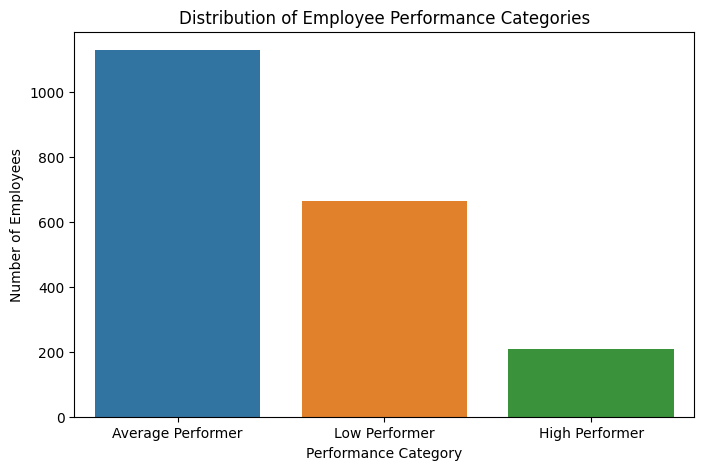

In [19]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train,
    x="Performance_Category",
    hue="Performance_Category",
    legend=False
)

plt.title("Distribution of Employee Performance Categories")
plt.xlabel("Performance Category")
plt.ylabel("Number of Employees")
plt.xticks()
plt.show()

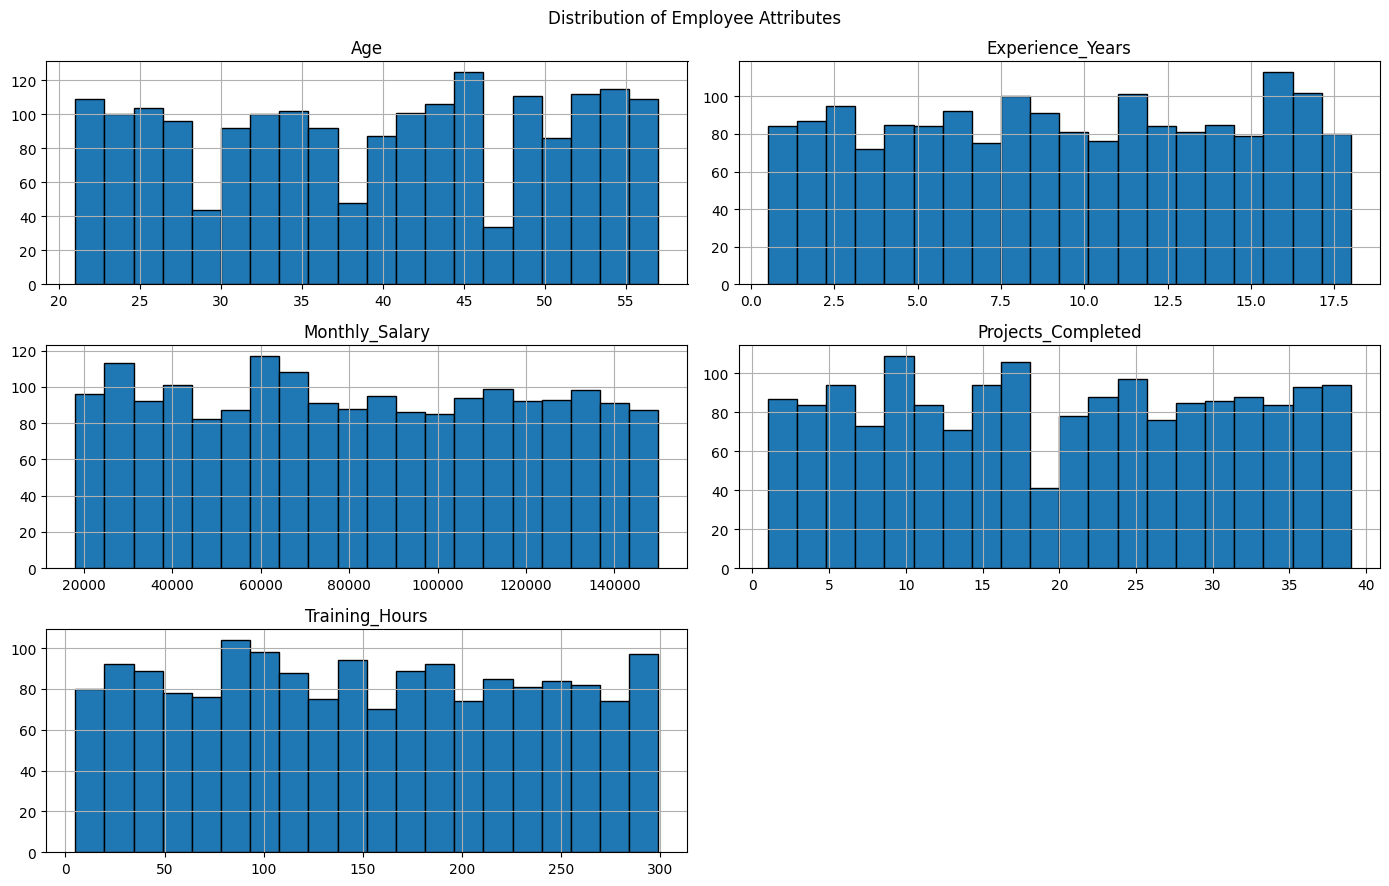

In [20]:
numeric_cols = [
    "Age",
    "Experience_Years",
    "Monthly_Salary",
    "Projects_Completed",
    "Training_Hours"
]

train[numeric_cols].hist(
    figsize=(14, 9),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Employee Attributes")
plt.tight_layout()
plt.show()

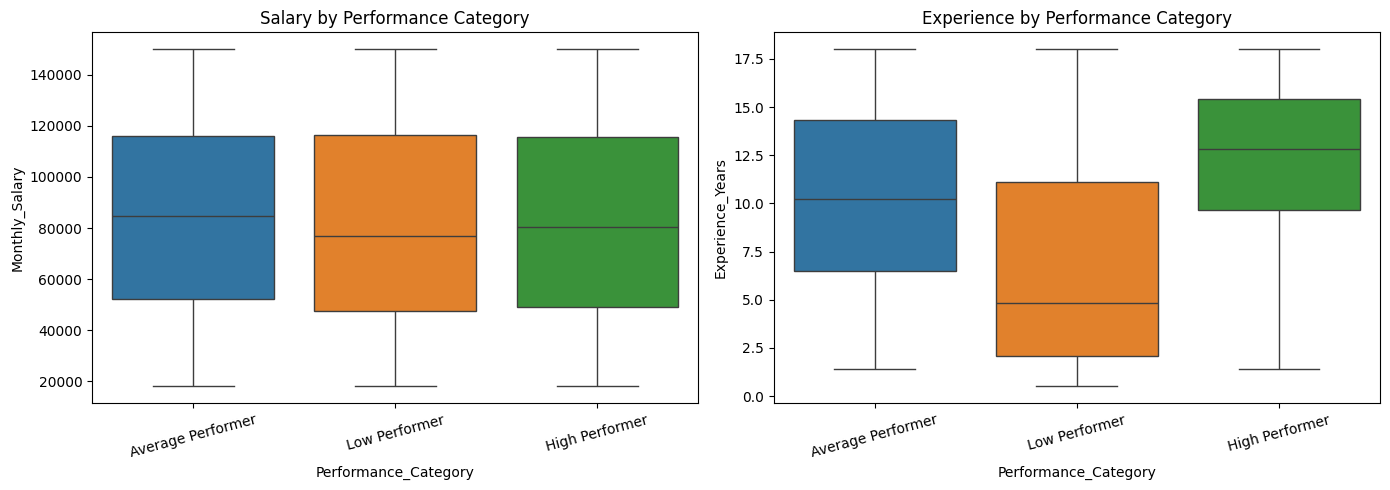

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=train,
    x="Performance_Category",
    y="Monthly_Salary",
    hue="Performance_Category",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Salary by Performance Category")
axes[0].tick_params(axis="x", rotation=15)

sns.boxplot(
    data=train,
    x="Performance_Category",
    y="Experience_Years",
    hue="Performance_Category",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Experience by Performance Category")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

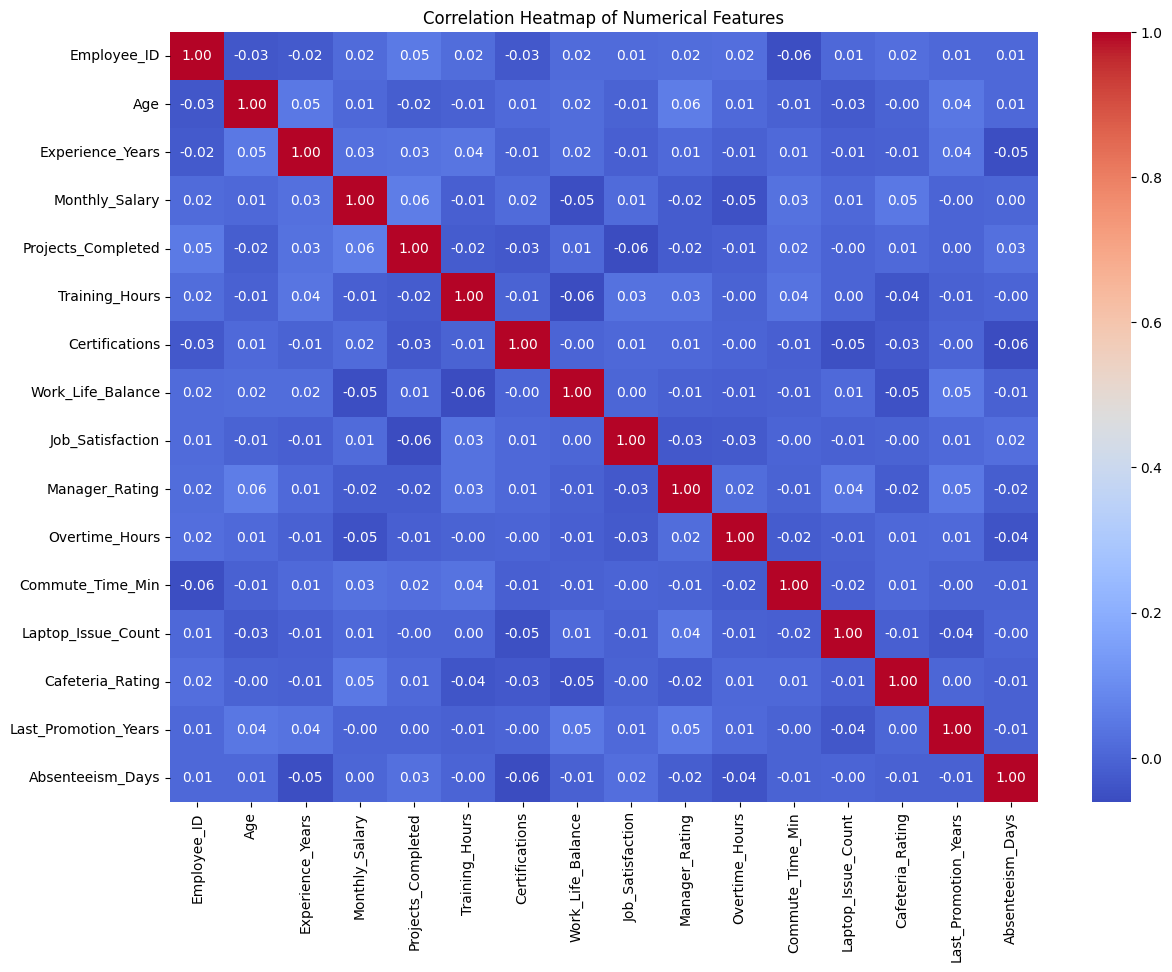

In [22]:
numeric_data = train.select_dtypes(include="number")

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

In [23]:
# Separate input features (X) and target (y)
X = train.drop(columns=["Employee_ID", "Performance_Category"])
y = train["Performance_Category"]

# Prepare the test features
X_test = test.drop(columns=["Employee_ID"])

print("Training features:", X.shape)
print("Target:", y.shape)
print("Test features:", X_test.shape)

Training features: (2000, 20)
Target: (2000,)
Test features: (500, 20)


In [24]:
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:")
print(numeric_cols)

print("\nCategorical columns:")
print(categorical_cols)

print("\nNumber of numerical columns:", len(numeric_cols))
print("Number of categorical columns:", len(categorical_cols))

Numerical columns:
['Age', 'Experience_Years', 'Monthly_Salary', 'Projects_Completed', 'Training_Hours', 'Certifications', 'Work_Life_Balance', 'Job_Satisfaction', 'Manager_Rating', 'Overtime_Hours', 'Commute_Time_Min', 'Laptop_Issue_Count', 'Cafeteria_Rating', 'Last_Promotion_Years', 'Absenteeism_Days']

Categorical columns:
['Gender', 'City', 'Education_Level', 'Department', 'Internet_Stability']

Number of numerical columns: 15
Number of categorical columns: 5


In [25]:
print("Missing values in training features:", X.isnull().sum().sum())
print("Missing values in test features:", X_test.isnull().sum().sum())

Missing values in training features: 4131
Missing values in test features: 1045


In [26]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Model training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Model training targets:", y_train.shape)
print("Validation targets:", y_val.shape)

Model training features: (1600, 20)
Validation features: (400, 20)
Model training targets: (1600,)
Validation targets: (400,)


In [ ]:
# model ( decision tree )


In [28]:
# Step 16: Preprocessing + Decision Tree

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Identify numerical and categorical columns
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
categorical_cols = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

#  ML pipeline
dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train the model
dt_model.fit(X_train, y_train)

# Predict validation data
dt_predictions = dt_model.predict(X_val)

# Calculate accuracy
dt_accuracy = accuracy_score(y_val, dt_predictions)

print("Decision Tree Validation Accuracy:",
      round(dt_accuracy * 100, 2), "%")

Decision Tree Validation Accuracy: 86.5 %


In [29]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val,
    dt_predictions,
    zero_division=0
))

                   precision    recall  f1-score   support

Average Performer       0.88      0.95      0.91       226
   High Performer       0.60      0.68      0.64        41
    Low Performer       0.95      0.77      0.85       133

         accuracy                           0.86       400
        macro avg       0.81      0.80      0.80       400
     weighted avg       0.87      0.86      0.87       400



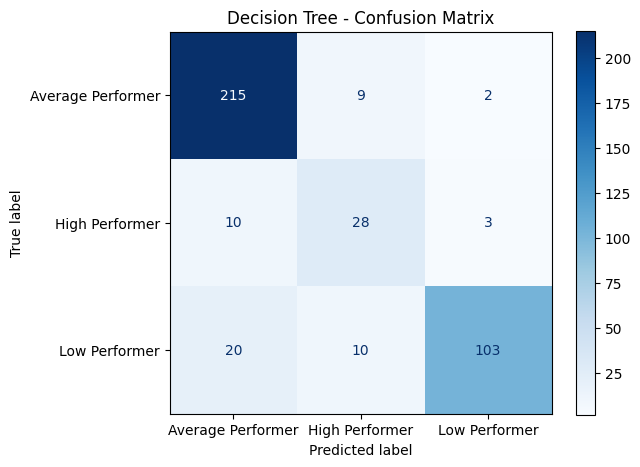

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    dt_predictions,
    xticks_rotation=0,
    cmap="Blues"
)

plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

In [32]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_val)

rf_accuracy = accuracy_score(y_val, rf_predictions)

print("Random Forest Validation Accuracy:",
      round(rf_accuracy * 100, 2), "%")

Random Forest Validation Accuracy: 88.0 %


In [33]:
results = pd.DataFrame([
    {
        "Model": "Decision Tree",
        "Validation Accuracy": dt_accuracy
    },
    {
        "Model": "Random Forest",
        "Validation Accuracy": rf_accuracy
    }
])

results = results.sort_values(
    by="Validation Accuracy",
    ascending=False
).reset_index(drop=True)

results

,Model,Validation Accuracy
0,Random Forest,0.880
1,Decision Tree,0.865


In [34]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

et_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", ExtraTreesClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

et_model.fit(X_train, y_train)

et_predictions = et_model.predict(X_val)

et_accuracy = accuracy_score(y_val, et_predictions)

print("Extra Trees Validation Accuracy:",
      round(et_accuracy * 100, 2), "%")

Extra Trees Validation Accuracy: 82.25 %


In [35]:
results = pd.DataFrame([
    {"Model": "Decision Tree", "Accuracy": dt_accuracy},
    {"Model": "Random Forest", "Accuracy": rf_accuracy},
    {"Model": "Extra Trees", "Accuracy": et_accuracy}
])

results = results.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

results["Accuracy (%)"] = (results["Accuracy"] * 100).round(2)

results

,Model,Accuracy,Accuracy (%)
0,Random Forest,0.8800,88.00
1,Decision Tree,0.8650,86.50
2,Extra Trees,0.8225,82.25


In [39]:
# cat boost

In [36]:
%pip install -q catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 4.9 MB/s eta 0:00:00


In [37]:
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, classification_report

X_train_cb = X_train.copy()
X_val_cb = X_val.copy()

cat_cols_cb = X_train_cb.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

for col in cat_cols_cb:
    X_train_cb[col] = X_train_cb[col].fillna("Missing").astype(str)
    X_val_cb[col] = X_val_cb[col].fillna("Missing").astype(str)

print("Categorical columns:", cat_cols_cb)

Categorical columns: ['Gender', 'City', 'Education_Level', 'Department', 'Internet_Stability']


In [38]:
cb_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.04,
    loss_function="MultiClass",
    random_seed=42,
    verbose=False,
    l2_leaf_reg=5
)

cb_model.fit(
    X_train_cb,
    y_train,
    cat_features=cat_cols_cb
)

cb_predictions = cb_model.predict(X_val_cb).ravel()

cb_accuracy = accuracy_score(y_val, cb_predictions)

print("CatBoost Validation Accuracy:",
      round(cb_accuracy * 100, 2), "%")

CatBoost Validation Accuracy: 88.5 %


In [40]:
results = pd.DataFrame([
    {"Model": "Decision Tree", "Accuracy": dt_accuracy},
    {"Model": "Random Forest", "Accuracy": rf_accuracy},
    {"Model": "Extra Trees", "Accuracy": et_accuracy},
    {"Model": "CatBoost", "Accuracy": cb_accuracy}
])

results["Accuracy (%)"] = (results["Accuracy"] * 100).round(2)

results = results.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

results

,Model,Accuracy,Accuracy (%)
0,CatBoost,0.8850,88.50
1,Random Forest,0.8800,88.00
2,Decision Tree,0.8650,86.50
3,Extra Trees,0.8225,82.25


In [41]:
print(classification_report(
    y_val,
    cb_predictions,
    zero_division=0
))


                   precision    recall  f1-score   support

Average Performer       0.85      0.99      0.91       226
   High Performer       0.95      0.51      0.67        41
    Low Performer       0.96      0.83      0.89       133

         accuracy                           0.89       400
        macro avg       0.92      0.78      0.82       400
     weighted avg       0.89      0.89      0.88       400



In [42]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    "classifier__n_estimators": [200, 400],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best 5-fold CV accuracy:", round(grid_search.best_score_ * 100, 2), "%")

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters: {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 4, 'classifier__n_estimators': 200}
Best 5-fold CV accuracy: 88.12 %


In [43]:
from sklearn.metrics import accuracy_score, classification_report

best_rf = grid_search.best_estimator_

tuned_predictions = best_rf.predict(X_val)
tuned_accuracy = accuracy_score(y_val, tuned_predictions)

print("Tuned Random Forest validation accuracy:",
      round(tuned_accuracy * 100, 2), "%")

print(classification_report(
    y_val,
    tuned_predictions,
    zero_division=0
))

Tuned Random Forest validation accuracy: 88.75 %
                   precision    recall  f1-score   support

Average Performer       0.88      0.97      0.92       226
   High Performer       0.73      0.66      0.69        41
    Low Performer       0.96      0.82      0.88       133

         accuracy                           0.89       400
        macro avg       0.86      0.82      0.83       400
     weighted avg       0.89      0.89      0.89       400



In [44]:
comparison = pd.DataFrame({
    "Model": ["Original Random Forest", "Tuned Random Forest"],
    "Validation Accuracy (%)": [
        round(rf_accuracy * 100, 2),
        round(tuned_accuracy * 100, 2)
    ]
})

comparison

,Model,Validation Accuracy (%)
0,Original Random Forest,88.00
1,Tuned Random Forest,88.75


In [45]:
# Get the best Random Forest model
best_rf = grid_search.best_estimator_

# Predict on validation data
tuned_predictions = best_rf.predict(X_val)

# Calculate accuracy
tuned_accuracy = accuracy_score(y_val, tuned_predictions)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", round(grid_search.best_score_ * 100, 2), "%")
print("Tuned Validation Accuracy:", round(tuned_accuracy * 100, 2), "%")

Best Parameters: {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 4, 'classifier__n_estimators': 200}
Best Cross-Validation Accuracy: 88.12 %
Tuned Validation Accuracy: 88.75 %


In [46]:
print(classification_report(y_val, tuned_predictions))

                   precision    recall  f1-score   support

Average Performer       0.88      0.97      0.92       226
   High Performer       0.73      0.66      0.69        41
    Low Performer       0.96      0.82      0.88       133

         accuracy                           0.89       400
        macro avg       0.86      0.82      0.83       400
     weighted avg       0.89      0.89      0.89       400



In [47]:
# Use the tuned model if GridSearchCV has completed
final_model = grid_search.best_estimator_

# Train on the complete training dataset
final_model.fit(X, y)

print("Final model trained successfully!")

Final model trained successfully!


In [48]:
# Remove Employee_ID because it is not a model feature
X_test = test.drop(columns=["Employee_ID"])

# Predict performance categories
test_predictions = final_model.predict(X_test)

print("Total predictions:", len(test_predictions))
print("\nFirst 10 predictions:")
print(test_predictions[:10])

Total predictions: 500

First 10 predictions:
['Average Performer' 'Average Performer' 'Average Performer'
 'Low Performer' 'Average Performer' 'Low Performer' 'Average Performer'
 'Average Performer' 'Average Performer' 'Average Performer']


In [49]:
submission = sample_submission.copy()

submission["Performance_Category"] = test_predictions

submission.to_csv("employee_performance_submission.csv", index=False)

print(submission.head())
print("\nSubmission shape:", submission.shape)

   Employee_ID Performance_Category
0        12001    Average Performer
1        12002    Average Performer
2        12003    Average Performer
3        12004        Low Performer
4        12005    Average Performer

Submission shape: (500, 2)


In [50]:
# Check submission dimensions
print("Shape:", submission.shape)

# Check column names
print("Columns:", submission.columns.tolist())

# Check for missing predictions
print("Missing values:\n", submission.isnull().sum())

# Check class distribution
print("\nPredicted class distribution:")
print(submission["Performance_Category"].value_counts())

# Check whether IDs match the test dataset
print(
    "Employee IDs match:",
    submission["Employee_ID"].equals(test["Employee_ID"])
)

Shape: (500, 2)
Columns: ['Employee_ID', 'Performance_Category']
Missing values:
 Employee_ID             0
Performance_Category    0
dtype: int64

Predicted class distribution:
Performance_Category
Average Performer    318
Low Performer        130
High Performer        52
Name: count, dtype: int64
Employee IDs match: True


In [51]:
from google.colab import files

files.download("employee_performance_submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:
print("Decision Tree:", round(dt_accuracy * 100, 2), "%")
print("Random Forest:", round(rf_accuracy * 100, 2), "%")
print("Extra Trees:", round(et_accuracy * 100, 2), "%")

if "cb_accuracy" in globals():
    print("CatBoost:", round(cb_accuracy * 100, 2), "%")

if "tuned_accuracy" in globals():
    print("Tuned Random Forest:", round(tuned_accuracy * 100, 2), "%")

Decision Tree: 86.5 %
Random Forest: 88.0 %
Extra Trees: 82.25 %
CatBoost: 88.5 %
Tuned Random Forest: 88.75 %


In [55]:
# verify
import os
import pandas as pd

submission = pd.read_csv("employee_performance_submission.csv")

print("File exists:", os.path.exists("employee_performance_submission.csv"))
print("Shape:", submission.shape)
print("Missing values:", submission.isnull().sum().sum())
print("IDs match test data:",
      submission["Employee_ID"].equals(test["Employee_ID"]))
print("Predicted classes:",
      submission["Performance_Category"].unique())

File exists: True
Shape: (500, 2)
Missing values: 0
IDs match test data: True
Predicted classes: ['Average Performer' 'Low Performer' 'High Performer']
